In [ ]:
# GPU preflight: stop early if this kernel cannot use CUDA.
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable in this notebook kernel. Select the Python interpreter "
        "named 4010-DeepLearning-gpu and run outside a GPU-restricted sandbox. "
        "Check nvidia-smi and the README GPU instructions."
    )
print("GPU:", torch.cuda.get_device_name(0), "| PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)


In [ ]:
import os

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
df.head()

### GPU check
Confirms which device PyTorch will train on. Every model below is moved to `device`.

In [ ]:
import random
import numpy as np
import torch

print('PyTorch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('CUDA version:', torch.version.cuda, '| cuDNN version:', torch.backends.cudnn.version())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print('Training on GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, training on CPU')

# A small matmul proves tensors actually land on the chosen device
probe = torch.randn(256, 256, device=device)
print('Test matmul ran on:', (probe @ probe).device)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

# Deterministic cuDNN kernels so GPU runs repeat exactly with the same seed
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

## Basic investigation

In [ ]:
print('Shape:', df.shape)
print('Range:', df.index.min(), '->', df.index.max())
print('Timestamps unique and evenly spaced (1 min):', df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta('1min')).all())
df.info()

In [ ]:
df.describe().T

### Missing values

In [ ]:
missing = df.isna()
print('Missing per column:')
print(missing.sum())
print(f'\nRows with any missing: {missing.any(axis=1).sum()} ({missing.any(axis=1).mean():.2%})')

# Missing values come in contiguous gaps; list the longest ones
row_missing = missing.any(axis=1)
gap_id = (row_missing != row_missing.shift()).cumsum()
gaps = row_missing[row_missing].groupby(gap_id[row_missing]).agg(
    start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size')
print(f'\nNumber of gaps: {len(gaps)}')
gaps.sort_values('minutes', ascending=False).head(10).reset_index(drop=True)

### Distributions

In [ ]:
df.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
plt.show()

### Correlations

In [ ]:
df.corr().round(2)

### Trends and seasonality

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
df['Global_active_power'].resample('D').mean().plot(ax=axes[0], title='Daily mean Global_active_power (kW)')
df['Global_active_power'].groupby(df.index.hour).mean().plot(ax=axes[1], kind='bar', title='Mean by hour of day')
df['Global_active_power'].groupby(df.index.month).mean().plot(ax=axes[2], kind='bar', title='Mean by month')
plt.tight_layout()
plt.show()

## Problem definition and data audit

| | |
|---|---|
| **Source** | UCI Individual Household Electric Power Consumption (#235), CC BY 4.0 |
| **Target** | `Global_active_power` (GAP), kW: the whole-house real power draw |
| **Native frequency** | 1 minute |
| **Resampling rule** | Hourly mean (an hour needs at least 30 recorded minutes, otherwise it counts as missing) |
| **Lookback / horizon** | 168 h (one week) in, next 24 h out |
| **Inputs** | Past 168 h of all 7 measured columns (lagged only) plus hour-of-day and day-of-week sin/cos |

**Operational meaning:** at hour *t* we forecast the household's load profile for the next day, using only data observed before *t*. That is the setting for day-ahead load planning and demand response.

In [ ]:
TARGET = 'Global_active_power'
LOOKBACK, HORIZON = 168, 24
DAY, WEEK = 24, 168  # seasonal periods in hours

audit = pd.Series({
    'Target': f'{TARGET} (kW)',
    'Coverage': f'{df.index.min()} -> {df.index.max()}',
    'Rows (1 min)': len(df),
    'Duplicate timestamps': df.index.duplicated().sum(),
    'Missing rows': f'{row_missing.sum()} ({row_missing.mean():.2%})',
    'Missing gaps': len(gaps),
    'Longest gap': f"{gaps['minutes'].max() / 60 / 24:.1f} days",
    'Lookback / horizon': f'{LOOKBACK} h / {HORIZON} h',
}, name='Value')
audit.to_frame()

## Resampling and imputation
* **Resample:** hourly mean. Hours with fewer than 30 recorded minutes are set to missing.
* **Short gaps (≤ 3 h):** forward fill, which carries the last observed hour forward.
* **Long gaps (up to about 5 days):** the value from the same hour one week earlier. Any remainder is forward-filled.

Every fill is **causal**: a missing hour is filled only from earlier hours. Interpolation would use the next observed hour, which could be a target hour of the same window. Nothing here is fitted to data either, so imputation cannot leak test statistics into training. The `imputed` mask is kept so we can report how much of each split is filled in.

In [ ]:
counts = df[TARGET].resample('h').count()
hourly_raw = df.resample('h').mean()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()

# Length of each run of missing hours
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)

hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):  # a second pass covers gaps whose previous week was also missing
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()  # only leading hours with no history can remain; drop them
imputed = imputed.loc[hourly.index]

assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly)} | imputed hours: {imputed.sum()} ({imputed.mean():.2%}), '
      f'of which short gaps: {short_gap.sum()}')

## Why GAP is the target, and why the other measurements must be lagged
The charts below use the hourly data **before imputation**, so filled-in values can't create artificial correlation.

In [ ]:
corr = hourly_raw.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title('Fig. 1 - Correlation matrix of hourly means')
plt.tight_layout()
plt.show()

In [ ]:
h = hourly_raw.dropna()
sub_cols = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

def sub_kw(frame):
    return frame[sub_cols] * 60 / 1000  # sub-meters are Wh per minute -> kW

print(f'Sub-meters cover on average {(sub_kw(h).sum(axis=1) / h[TARGET]).mean():.0%} of GAP')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

v = h['Voltage'].mean()
axes[0].scatter(h[TARGET], h['Global_intensity'], s=2, alpha=0.3)
x = np.linspace(0, h[TARGET].max(), 100)
axes[0].plot(x, x * 1000 / v, 'r', label=f'I = P·1000 / V  (V = {v:.0f})')
axes[0].set(xlabel='Global_active_power (kW)', ylabel='Global_intensity (A)',
            title='Fig. 2a - Intensity is GAP divided by voltage')
axes[0].legend()

week = hourly_raw.loc['2008-01-07':'2008-01-13']
parts = sub_kw(week)
parts.columns = ['Kitchen (SM1)', 'Laundry (SM2)', 'Water heater / AC (SM3)']
parts['Unmetered rest'] = week[TARGET] - parts.sum(axis=1)
axes[1].stackplot(parts.index, parts.T, labels=parts.columns, alpha=0.8)
axes[1].plot(week.index, week[TARGET], 'k', lw=1, label='GAP (total)')
axes[1].set(ylabel='kW', title='Fig. 2b - Sub-meters are parts of GAP (week of 7 Jan 2008)')
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
lags = range(49)
xcorr = pd.DataFrame({col: [hourly_raw[TARGET].corr(hourly_raw[col].shift(k)) for k in lags]
                      for col in hourly_raw.columns}, index=lags)
acf_lags = range(1, 2 * WEEK + 1)
acf = pd.Series([hourly_raw[TARGET].autocorr(k) for k in acf_lags], index=acf_lags)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for col in xcorr.columns:
    style = dict(color='k', ls='--', lw=2) if col == TARGET else {}
    label = 'GAP (autocorrelation)' if col == TARGET else col
    axes[0].plot(xcorr.index, xcorr[col], label=label, **style)
axes[0].set(xlabel='Lag k (hours)', ylabel='corr(GAP_t, X_{t-k})',
            title='Fig. 3a - Lagged cross-correlation with GAP')
axes[0].legend(fontsize=8)

axes[1].plot(acf.index, acf)
for k in (DAY, WEEK, 2 * WEEK):
    axes[1].axvline(k, color='r', ls=':', lw=1)
axes[1].set(xlabel='Lag (hours)', ylabel='Autocorrelation',
            title='Fig. 3b - GAP autocorrelation (peaks at 24 h and 168 h)')

plt.tight_layout()
plt.show()

xcorr.loc[[0, 1, 24, 48]].T.round(2).rename(columns=lambda k: f'lag {k} h')

**Why GAP is the target**
* GAP is the total real power the household draws, which is what the meter bills. That makes forecasting it directly useful.
* `Global_intensity` is the same quantity in amps (Fig. 1 r ≈ 1.00, Fig. 2a: it lies on I = P·1000/V). Forecasting it would be the same task in different units.
* The sub-meters only cover some circuits (Fig. 2b). A large "unmetered" share remains, so none of them describes the whole house.
* `Voltage` mostly reflects the grid, and `Global_reactive_power` isn't billed. Neither describes household consumption.

**Why the other measurements are lagged inputs only**
* At lag 0, `Global_intensity` is almost perfectly correlated with GAP (Fig. 3a). Feeding the same-hour value into the model would leak the answer: the "forecast" would just be a unit conversion. We wouldn't have that value at forecast time anyway.
* Once lagged (k ≥ 1), every feature's correlation falls to roughly GAP's own autocorrelation level or below. They add context (for example, which appliances were recently on) without revealing the target. This is the spec §3 rule: contemporaneous measurements may only be used as lagged inputs.
* The autocorrelation peaks at 24 h and 168 h (Fig. 3b) show daily and weekly cycles. That justifies a one-week lookback.

## Chronological split (60 / 20 / 20) and windows
* The split is by time, never shuffled globally. The scaler is **fit on training rows only**.
* Each window holds 168 hours of inputs (`t-168 … t-1`) and the 24 target hours `t … t+23`.
* For validation and test windows, the lookback may reach back into the previous split. That is past data, so it's allowed, but **targets always stay inside their own split**.

In [ ]:
features = hourly.copy()
features['hour_sin'] = np.sin(2 * np.pi * features.index.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * features.index.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * features.index.dayofweek / 7)
features['dow_cos'] = np.cos(2 * np.pi * features.index.dayofweek / 7)
FEATURES = list(features.columns)
TARGET_IDX = FEATURES.index(TARGET)

n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}

pd.DataFrame([{'split': s, 'start': features.index[a], 'end': features.index[b - 1], 'hours': b - a,
               'imputed %': round(imputed.iloc[a:b].mean() * 100, 2)}
              for s, (a, b) in splits.items()]).set_index('split')

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4))
daily = features[TARGET].resample('D').mean()
for s, (a, b) in splits.items():
    part = daily.loc[features.index[a]:features.index[b - 1]]
    ax.plot(part.index, part, label=s)
ax.set(ylabel='GAP daily mean (kW)', title='Fig. 4 - Chronological train / validation / test split')
ax.legend()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler().fit(features.iloc[:train_end])  # train rows only
X_all = x_scaler.transform(features).astype(np.float32)

def to_kw(y):
    """Undo the target scaling so all metrics are in kW."""
    return y * x_scaler.scale_[TARGET_IDX] + x_scaler.mean_[TARGET_IDX]

def make_windows(start, end):
    """Windows whose 24-h target lies in rows [start, end); the lookback may come from earlier rows."""
    t = np.arange(max(start, LOOKBACK), end - HORIZON + 1)
    X = np.stack([X_all[i - LOOKBACK:i] for i in t])
    y = np.stack([X_all[i:i + HORIZON, TARGET_IDX] for i in t])
    return X, y, t

data = {s: make_windows(a, b) for s, (a, b) in splits.items()}
Y_kw = {s: to_kw(y) for s, (_, y, _) in data.items()}

for s, (X, y, t) in data.items():
    print(f'{s:5s}  X {X.shape}  y {y.shape}  targets {features.index[t[0]]} -> {features.index[t[-1] + HORIZON - 1]}')
X_train, y_train, t_train = data['train']
X_val, y_val, t_val = data['val']
assert X_train.shape[1:] == (LOOKBACK, len(FEATURES)) and y_train.shape[1] == HORIZON
assert t_train[-1] + HORIZON <= train_end and t_val[-1] + HORIZON <= val_end  # no target crosses a split

## Baselines (non-neural)
All models make the same 24-hour forecast from the same windows and are scored in kW with MAE and RMSE.
* **Persistence:** repeat the last observed hour.
* **Seasonal naive (day):** the last 24 hours repeat.
* **Seasonal naive (week):** the same 24 hours one week earlier repeat.
* **Ridge regression** on the flattened 168 × 11 window. Alpha is chosen on validation.

Until the final comparison, only validation scores are shown. The test set stays untouched.

In [ ]:
import time
from sklearn.linear_model import Ridge

def evaluate(y_true, y_pred):
    err = y_pred - y_true
    return {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean())}

def flat(X):
    return X.reshape(len(X), -1)

# Every model is registered once: a predictor (scaled windows -> scaled 24-h forecasts) plus its cost info
predictors, info, preds = {}, {}, {}

def register(name, predict_fn, params=0, secs=0.0, seed='-'):
    predictors[name] = predict_fn
    for split in data:  # drop forecasts cached from an earlier model with this name
        preds.pop((name, split), None)
    info[name] = {'params': params, 'train time (s)': secs, 'seed': seed}

def prediction(name, split):
    """kW forecasts of one model on one split, computed once and cached."""
    if (name, split) not in preds:
        preds[name, split] = to_kw(predictors[name](data[split][0]))
    return preds[name, split]

def score(split):
    return pd.DataFrame({name: evaluate(Y_kw[split], prediction(name, split))
                         for name in predictors}).T.add_prefix(f'{split} ')

def table(*splits):
    return pd.concat([score(s) for s in splits], axis=1).join(pd.DataFrame(info).T)

def seasonal_naive(period):
    """Forecast each hour with the value `period` hours earlier (taken from the lookback window)."""
    assert HORIZON <= period <= LOOKBACK
    return lambda X: X[:, LOOKBACK - period:LOOKBACK - period + HORIZON, TARGET_IDX]

register('Persistence', lambda X: np.repeat(X[:, -1:, TARGET_IDX], HORIZON, axis=1))
register('Seasonal naive (day)', seasonal_naive(DAY))
register('Seasonal naive (week)', seasonal_naive(WEEK))

Xf_train, Xf_val = flat(X_train), flat(X_val)
ridge_mae, ridge_fits = {}, {}
for alpha in [1, 10, 100, 1000, 10000]:
    start = time.perf_counter()
    model = Ridge(alpha=alpha).fit(Xf_train, y_train)
    ridge_fits[alpha] = (model, time.perf_counter() - start)
    ridge_mae[alpha] = evaluate(Y_kw['val'], to_kw(model.predict(Xf_val)))['MAE']
best_alpha = min(ridge_mae, key=ridge_mae.get)
print('Ridge validation MAE by alpha:', {a: round(m, 4) for a, m in ridge_mae.items()}, '-> alpha =', best_alpha)

ridge, ridge_secs = ridge_fits[best_alpha]
register('Ridge', lambda X: ridge.predict(flat(X)), ridge.coef_.size + ridge.intercept_.size, ridge_secs)

table('val')

## MLP and CNN (PyTorch)
Both use the same windows, horizon, loss (MSE on scaled GAP), optimizer (Adam), batch size and early-stopping rule (at most 100 epochs, stopping after 30 epochs without validation improvement, then restore the best weights). They are scored with the same metrics as the baselines.
* **MLP:** flattens the 168 × 11 window, then fully connected layers.
* **CNN:** two Conv1d + max-pool blocks slide over time. The result is flattened rather than globally averaged, so the model keeps track of *when* in the week a pattern happened.

In [ ]:
import copy
from functools import partial
from torch import nn

BATCH = 64
MAX_EPOCHS, PATIENCE = 100, 30

class MLP(nn.Module):
    def __init__(self, hidden=256, layers=2, dropout=0.2):
        super().__init__()
        dims = [LOOKBACK * len(FEATURES)] + [hidden] * layers
        blocks = [nn.Flatten()]
        for d_in, d_out in zip(dims, dims[1:]):
            blocks += [nn.Linear(d_in, d_out), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*blocks, nn.Linear(dims[-1], HORIZON))

    def forward(self, x):
        return self.net(x)

class CNN(nn.Module):
    def __init__(self, filters=64, kernel=5, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(len(FEATURES), filters, kernel, padding='same'), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(filters, filters, kernel, padding='same'), nn.ReLU(), nn.MaxPool1d(2),
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(filters * (LOOKBACK // 4), HORIZON))

    def forward(self, x):
        return self.net(x.transpose(1, 2))  # (batch, time, features) -> (batch, channels, time)

# Grid-search spaces per model family (used in the grid search section)
MODEL_SPECS = {
    'MLP': (MLP, {'hidden': [128, 256, 512], 'layers': [1, 2], 'dropout': [0.0, 0.2],
                  'lr': [1e-3, 3e-4], 'batch_size': [32, 64, 128]}),
    'CNN': (CNN, {'filters': [32, 64, 128], 'kernel': [3, 5], 'dropout': [0.0, 0.2],
                  'lr': [1e-3, 3e-4], 'batch_size': [32, 64, 128]}),
}

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(device)).cpu() for xb in torch.from_numpy(X).split(1024)]).numpy()

def register_model(name, model, secs):
    register(name, partial(predict, model), count_params(model), secs, SEED)

def fit(build, train, val, lr=1e-3, batch_size=BATCH, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    """Train with early stopping on validation MSE; returns the best model, loss history and train time."""
    set_seed()
    model = build().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    # Copy the data to the device once, instead of once per batch
    X_tr, y_tr = (torch.from_numpy(a).to(device) for a in train)
    X_va, y_va = (torch.from_numpy(a).to(device) for a in val)
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start = time.perf_counter()
    for _ in range(max_epochs):
        model.train()
        total = 0.0
        for idx in torch.randperm(len(X_tr), device=device).split(batch_size):
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = sum(loss_fn(model(xb), yb).item() * len(xb)
                           for xb, yb in zip(X_va.split(1024), y_va.split(1024))) / len(X_va)
        history['train'].append(total.item() / len(X_tr))
        history['val'].append(val_loss)
        if val_loss < best_loss:
            best_loss, wait = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start

In [ ]:
histories = {}
for name, (cls, _) in MODEL_SPECS.items():
    model, histories[name], secs = fit(cls, (X_train, y_train), (X_val, y_val))
    register_model(name, model, secs)
    print(f'{name}: {len(histories[name]["val"])} epochs, {secs:.1f} s')

fig, axes = plt.subplots(1, len(histories), figsize=(7 * len(histories), 4), squeeze=False)
for ax, (name, hist) in zip(axes[0], histories.items()):
    ax.plot(hist['train'], label='train')
    ax.plot(hist['val'], label='validation')
    ax.axvline(int(np.argmin(hist['val'])), color='k', ls=':', label='best epoch')
    ax.set(xlabel='Epoch', ylabel='MSE (scaled)', title=f'Fig. 5 - {name} learning curves')
    ax.legend()
plt.tight_layout()
plt.show()

val_scores = table('val')
val_scores

**Reading the learning curves:** if the validation loss bottoms out early while the training loss keeps falling, the model is overfitting. Early stopping keeps the weights from the best validation epoch (the dotted line).

## Grid search (validation only)
The model family (MLP or CNN) with the lower validation MAE above is tuned. The setup is fixed before any results are seen:
* **Objective:** validation MAE (kW).
* **Search space** (both families share lr and batch size):
  * MLP: hidden {128, 256, 512} × layers {1, 2} × dropout {0, 0.2}
  * CNN: filters {32, 64, 128} × kernel {3, 5} × dropout {0, 0.2}
  * Training: lr {1e-3, 3e-4} × batch size {32, 64, 128}
* **Budget:** 72 trials, at most 100 epochs each, early stopping with patience 30, seed 42.

The test set isn't used here.

In [ ]:
import itertools
import os

family = val_scores.loc[list(MODEL_SPECS), 'val MAE'].idxmin()
cls, grid = MODEL_SPECS[family]
print('Tuning', family)

trials, best = [], {'val MAE': float('inf')}
for values in itertools.product(*grid.values()):
    cfg = dict(zip(grid, values))
    train_cfg = {k: cfg.pop(k) for k in ('lr', 'batch_size')}  # passed to fit(), not to the model
    model, hist, secs = fit(lambda: cls(**cfg), (X_train, y_train), (X_val, y_val), **train_cfg)
    mae = evaluate(Y_kw['val'], to_kw(predict(model, X_val)))['MAE']
    trials.append({**cfg, **train_cfg, 'val MAE': mae, 'epochs': len(hist['val']), 'train time (s)': secs})
    if mae < best['val MAE']:
        best = {'val MAE': mae, 'model': model, 'cfg': cfg, 'train_cfg': train_cfg, 'secs': secs}

trials = pd.DataFrame(trials)
trials.sort_values('val MAE').reset_index(drop=True)

In [ ]:
fig, ax = plt.subplots(figsize=(max(12, 0.25 * len(trials)), 4))
labels = trials.drop(columns=['val MAE', 'epochs', 'train time (s)']).astype(str).agg(', '.join, axis=1)
ax.bar(range(len(trials)), trials['val MAE'], color=['C3' if m == best['val MAE'] else 'C0' for m in trials['val MAE']])
ax.axhline(val_scores.loc[family, 'val MAE'], color='k', ls='--', label=f'untuned {family}')
ax.set_xticks(range(len(trials)), labels, rotation=90, fontsize=7)
ax.set(ylabel='Validation MAE (kW)', title=f'Fig. 6 - {family} grid search trials (best in red)')
ax.legend()
plt.tight_layout()
plt.show()

tuned = f'{family} (tuned)'
register_model(tuned, best['model'], best['secs'])

os.makedirs('models', exist_ok=True)
torch.save({'family': family, 'config': best['cfg'], 'train_config': best['train_cfg'], 'state_dict': best['model'].state_dict(),
            'lookback': LOOKBACK, 'horizon': HORIZON, 'target': TARGET, 'features': FEATURES,
            'x_mean': x_scaler.mean_.tolist(), 'x_scale': x_scaler.scale_.tolist()},
           'models/stage1_best_gpu.pt')
print('Best config:', best['cfg'], '|', best['train_cfg'], f"| val MAE {best['val MAE']:.4f} kW -> saved to models/stage1_best_gpu.pt")

## Final comparison on the test set
All models are now locked, so the test set is evaluated **once**. "Improvement" is the test-MAE reduction relative to the better seasonal-naive baseline, where "better" was chosen on validation.

In [ ]:
results = table('val', 'test')
reference = results.loc[['Seasonal naive (day)', 'Seasonal naive (week)'], 'val MAE'].idxmin()
results['improvement vs baseline (%)'] = 100 * (1 - results['test MAE'] / results.loc[reference, 'test MAE'])
print('Table 1 - Model comparison (kW). Reference baseline:', reference)
results.round(4)

In [ ]:
X_test, _, t_test = data['test']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in predictors:
    step_mae = np.abs(prediction(name, 'test') - Y_kw['test']).mean(axis=0)
    axes[0].plot(range(1, HORIZON + 1), step_mae, marker='.', label=name)
axes[0].set(xlabel='Hours ahead', ylabel='Test MAE (kW)', title='Fig. 7a - Error by forecast step')
axes[0].legend(fontsize=8)

i = len(X_test) // 2  # fixed rule (middle of the test set), chosen before looking at forecasts
hours = features.index[t_test[i]:t_test[i] + HORIZON]
axes[1].plot(hours, Y_kw['test'][i], 'k', lw=2, label='Actual')
for name in [reference, 'Ridge', tuned]:
    axes[1].plot(hours, prediction(name, 'test')[i], label=name)
axes[1].set(ylabel='GAP (kW)', title=f'Fig. 7b - 24 h test forecast starting {hours[0]}')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Conclusion and next risk
**Conclusion:** The tuned CNN reaches a test MAE of 0.436 kW, 19.9% better than the seasonal-naive (week) reference. But Ridge gets 0.442 kW with a quarter of the parameters and 1/50 of the training time, and has a slightly lower RMSE. So most of the gain over the naive baselines comes from a *linear* weighting of the past week, and the CNN adds only about 0.005 kW. On test, seasonal naive (day) turns out to be the stronger naive baseline (0.527), and the tuned CNN still beats it by 17.1%.

**Unresolved risk to investigate next:**The test split is the most heavily imputed part of the data (3.50% of hours, vs 0.33% in training). It includes the two longest gaps (Aug and Sep 2010, about 5 days each), which were filled with the previous week's values, so part of the test score measures how well the model reproduces our own imputation rather than real consumption. Next we will report test metrics with imputed hours excluded. We also plan an ablation that removes features which may add little once lagged (voltage, reactive power and the sub-meters, whose lagged correlation with GAP is at or below GAP's own autocorrelation), to check whether they help beyond past GAP. The series has strong daily and weekly cycles and a yearly trend, so we will test whether making it stationary helps, either by having the model predict the change from the same hour last week or by using a seasonal decomposition. The decomposition must be computed causally from the lookback window only, because a full-series STL would leak future values. Finally, early stopping consistently selected weights from the first few epochs, which suggests the models overfit almost immediately. Recurrent and attention-based models (LSTM/GRU, Transformer) may use the 168-hour sequence better than the flattened MLP or fixed-window CNN.

## Stationarity experiment: why we kept the original inputs

We investigated whether weekly differencing improved forecasting before deciding how to proceed. On the **training target only**, the original series gave ADF p ≈ 6.2 × 10⁻²⁷ and KPSS p ≤ 0.01 (conflicting evidence); the weekly-differenced series gave ADF p < 0.001 and KPSS p ≥ 0.10, consistent with level stationarity under these test settings. KPSS p-values are bounded by its lookup table, and these tests do not prove stationarity or establish that every input feature is stationary.

The table below records the completed follow-up experiments, not a fresh model run. All compared MLP variants used the same eligible forecast origins, and the two CNN variants used the same eligible origins and default architecture. The measured inputs were either standardized levels, weekly differences, or both; the calendar inputs stayed unchanged. Weekly-difference forecasts were converted back to kW before scoring. The model names below are shorthand for the tested transformations, not a guarantee of stationarity.

In [ ]:
import pandas as pd

# Recorded results from AISE4010_Project_Group11_Stationarity.ipynb and its follow-up MLP test.
stationarity_summary = pd.DataFrame([
    {'Model': 'MLP: non-stationary inputs and outputs', 'Validation MAE': 0.46283082, 'Test MAE': 0.45884181, 'Test RMSE': 0.60222073},
    {'Model': 'MLP: stationary output', 'Validation MAE': 0.47305334, 'Test MAE': 0.48033214, 'Test RMSE': 0.66200820},
    {'Model': 'MLP: levels + stationary inputs and stationary output', 'Validation MAE': 0.47417902, 'Test MAE': 0.48101617, 'Test RMSE': 0.67013733},
    {'Model': 'MLP: stationary inputs and output only', 'Validation MAE': 0.516698, 'Test MAE': float('nan'), 'Test RMSE': float('nan')},
    {'Model': 'CNN: non-stationary inputs and outputs', 'Validation MAE': 0.460137, 'Test MAE': 0.460389, 'Test RMSE': 0.600135},
    {'Model': 'CNN: stationary inputs and outputs', 'Validation MAE': 0.514551, 'Test MAE': 0.522420, 'Test RMSE': 0.718701},
]).set_index('Model')
print('Recorded forecast errors (kW); blank test values were not evaluated.')
stationarity_summary.round(4)

Recorded forecast errors (kW); blank test values were not evaluated.


,Validation MAE,Test MAE,Test RMSE
Model,,,
MLP: non-stationary inputs and outputs,0.4628,0.4588,0.6022
MLP: stationary output,0.4731,0.4803,0.6620
MLP: levels + stationary inputs and stationary output,0.4742,0.4810,0.6701
MLP: stationary inputs and output only,0.5167,NaN,NaN
CNN: non-stationary inputs and outputs,0.4601,0.4604,0.6001
CNN: stationary inputs and outputs,0.5146,0.5224,0.7187


The level-based MLP and CNN achieved lower validation MAE and test RMSE than their tested differenced counterparts. Combining level and differenced inputs did not improve the MLP either. We therefore **retain the original level-based approach** for the project rather than adopting weekly differencing based on this experiment. More stationary-looking data did not automatically produce better forecasts here.

These results use one seed and the tested default architectures and training settings; they do not prove that other transformations or tuned models cannot help. The 72-trial Stage 1 search tuned the original model family, not each differenced variant. The test set was already viewed during Stage 1 and the differenced MLP test comparisons were follow-up analyses, so test results are not an untouched final evaluation. The full diagnostic cells, training code and CNN results are in `AISE4010_Project_Group11_Stationarity.ipynb`; the two additional differenced-MLP test values above were obtained in a separate follow-up run.

## Smoke test
A quick end-to-end check for the TA, which takes seconds and doesn't need the grid search to be re-run:
1. Reload the saved checkpoint and predict with it.
2. Train the same architecture for one epoch on 2,000 windows.

In [ ]:
ckpt = torch.load('models/stage1_best_gpu.pt', map_location=device)
smoke_cls = MODEL_SPECS[ckpt['family']][0]

reloaded = smoke_cls(**ckpt['config']).to(device)
reloaded.load_state_dict(ckpt['state_dict'])

X_s, y_s = X_train[:2000], y_train[:2000]
smoke_model, _, _ = fit(lambda: smoke_cls(**ckpt['config']), (X_s, y_s), (X_s[:200], y_s[:200]),
                        max_epochs=1, **ckpt['train_config'])

for out in (predict(reloaded, X_val[:200]), predict(smoke_model, X_val[:200])):
    assert out.shape == (200, HORIZON) and np.isfinite(out).all()
print('Smoke test passed on', device, '| output shape', out.shape)

# Stage 2 — Recurrent models, TCN and validation-only selection

This section extends Stage 1 without changing its code. We retain the same chronological split, training-only scaler, input features, 168-hour windows, 24-hour targets and kW metrics. Level-based inputs are retained based on the stationarity experiment above. The historical Stage 1 test results have already been viewed; Stage 2 model development, tuning and finalist selection use validation data only.

Following Lab 6, we compare a stacked simple RNN, a single-layer LSTM and a stacked GRU. RNNs pass a hidden state through time; LSTM and GRU gates regulate information flow. The TCN uses causal convolutions, expanding dilations and residual connections (Lecture 6). Recurrent gradients are clipped to norm 1.0. All new models use Adam, MSE, seed 42, at most 100 epochs and early stopping after 30 epochs without a better validation MSE; best weights are restored.

### Search contract — defined before Stage 2 results

First train each new model once and compare its validation MAE with the **untuned** Stage 1 MLP and CNN. Tune the best of those six neural families on validation only. Every family has exactly 32 combinations: two choices each for width, depth or kernel, dropout, learning rate and batch size. Epoch cap = 100; patience = 30; objective = validation MAE in kW after restoring minimum-validation-MSE weights; ties use the first grid combination.

| Family | Width | Depth or kernel | Dropout | Learning rate | Batch |
|---|---|---|---|---|---|
| RNN / LSTM / GRU | 32, 64 | 1, 2 layers | 0, 0.2 | 0.001, 0.0003 | 64, 128 |
| TCN | 32, 64 channels | kernel 3, 5 | 0, 0.2 | 0.001, 0.0003 | 64, 128 |
| MLP | 128, 256 | 1, 2 layers | 0, 0.2 | 0.001, 0.0003 | 64, 128 |
| CNN | 32, 64 filters | kernel 3, 5 | 0, 0.2 | 0.001, 0.0003 | 64, 128 |

TCN trials use two convolutions at each dilation 1, 2, 4, 8, 16, 32. For kernel 3 the receptive field is `1 + 2 × (3 − 1) × (1 + 2 + 4 + 8 + 16 + 32) = 253` hours; kernel 5 covers 505 hours. Both cover the 168-hour input.

In [28]:
import itertools
import torch.nn.functional as F

class Stage2Recurrent(nn.Module):
    def __init__(self, kind, hidden=64, layers=1, dropout=0.2):
        super().__init__()
        cell = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind]
        self.kind = kind
        self.recurrent = nn.ModuleList()
        for i in range(layers):
            input_size = len(FEATURES) if i == 0 else hidden
            output_size = hidden if i == 0 else hidden // 2
            self.recurrent.append(cell(input_size, output_size, batch_first=True))
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden if layers == 1 else hidden // 2, HORIZON)

    def forward(self, x):
        for layer in self.recurrent:
            x, _ = layer(x)
        return self.head(self.dropout(x[:, -1, :]))

class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel, dilation):
        super().__init__()
        self.left_pad = (kernel - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.left_pad, 0)))

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, channels, kernel, dilation, dropout):
        super().__init__()
        self.net = nn.Sequential(CausalConv1d(in_channels, channels, kernel, dilation), nn.ReLU(),
                                 nn.Dropout(dropout), CausalConv1d(channels, channels, kernel, dilation),
                                 nn.ReLU(), nn.Dropout(dropout))
        self.skip = nn.Identity() if in_channels == channels else nn.Conv1d(in_channels, channels, 1)

    def forward(self, x):
        return F.relu(self.net(x) + self.skip(x))

class Stage2TCN(nn.Module):
    def __init__(self, channels=32, kernel=3, dropout=0.2):
        super().__init__()
        self.dilations = (1, 2, 4, 8, 16, 32)
        self.receptive_field = 1 + 2 * (kernel - 1) * sum(self.dilations)
        self.blocks = nn.Sequential(*[TemporalBlock(len(FEATURES) if i == 0 else channels,
                                                     channels, kernel, d, dropout)
                                      for i, d in enumerate(self.dilations)])
        self.head = nn.Linear(channels, HORIZON)

    def sequence_features(self, x):
        return self.blocks(x.transpose(1, 2))

    def forward(self, x):
        return self.head(self.sequence_features(x)[:, :, -1])

def build_stage2(family_name, **cfg):
    if family_name in ('RNN', 'LSTM', 'GRU'):
        return Stage2Recurrent(family_name, **cfg)
    if family_name == 'TCN':
        return Stage2TCN(**cfg)
    return {'MLP': MLP, 'CNN': CNN}[family_name](**cfg)

STAGE2_DEFAULTS = {
    'RNN': {'hidden': 64, 'layers': 2, 'dropout': 0.2},
    'LSTM': {'hidden': 64, 'layers': 1, 'dropout': 0.2},
    'GRU': {'hidden': 64, 'layers': 2, 'dropout': 0.2},
    'TCN': {'channels': 32, 'kernel': 3, 'dropout': 0.2},
}
STAGE2_GRIDS = {
    **{name: {'hidden': [32, 64], 'layers': [1, 2], 'dropout': [0.0, 0.2],
              'lr': [1e-3, 3e-4], 'batch_size': [64, 128]} for name in ('RNN', 'LSTM', 'GRU')},
    'TCN': {'channels': [32, 64], 'kernel': [3, 5], 'dropout': [0.0, 0.2],
            'lr': [1e-3, 3e-4], 'batch_size': [64, 128]},
    'MLP': {'hidden': [128, 256], 'layers': [1, 2], 'dropout': [0.0, 0.2],
            'lr': [1e-3, 3e-4], 'batch_size': [64, 128]},
    'CNN': {'filters': [32, 64], 'kernel': [3, 5], 'dropout': [0.0, 0.2],
            'lr': [1e-3, 3e-4], 'batch_size': [64, 128]},
}
assert all(np.prod([len(v) for v in grid.values()]) == 32 for grid in STAGE2_GRIDS.values())

In [29]:
def stage2_sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()

def fit_stage2(family_name, config, train, val, lr=1e-3, batch_size=64, max_epochs=100, patience=30):
    set_seed()
    model = build_stage2(family_name, **config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xtr, ytr = (torch.from_numpy(a).to(device) for a in train)
    Xva, yva = (torch.from_numpy(a).to(device) for a in val)
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), None, 0
    stage2_sync(); start = time.perf_counter()
    for epoch in range(max_epochs):
        model.train(); total = 0.0
        for idx in torch.randperm(len(Xtr), device=device).split(batch_size):
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            if family_name in ('RNN', 'LSTM', 'GRU'):
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.detach() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = sum(loss_fn(model(x), y).item() * len(x)
                           for x, y in zip(Xva.split(1024), yva.split(1024))) / len(Xva)
        history['train'].append(float(total.item() / len(Xtr)))
        history['val'].append(float(val_loss))
        if val_loss < best_loss:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    stage2_sync(); seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    return model, history, seconds

### Architecture and pipeline smoke checks

These checks use small synthetic and training slices. The TCN causality check changes only future positions and verifies that earlier sequence features do not change. It is not a test-set evaluation.

In [30]:
assert t_train[-1] + HORIZON <= train_end and t_val[-1] + HORIZON <= val_end
assert X_train.shape[1:] == (LOOKBACK, len(FEATURES)) and y_train.shape[1] == HORIZON
for name, cfg in STAGE2_DEFAULTS.items():
    net = build_stage2(name, **cfg).to(device).eval()
    with torch.no_grad():
        out = net(torch.randn(2, LOOKBACK, len(FEATURES), device=device))
    assert out.shape == (2, HORIZON) and torch.isfinite(out).all()
    print(name, 'output:', tuple(out.shape), '| parameters:', count_params(net))
tcn_check = Stage2TCN().to(device).eval()
assert tcn_check.receptive_field >= LOOKBACK
x = torch.randn(2, LOOKBACK, len(FEATURES), device=device)
x_changed = x.clone(); x_changed[:, 100:] += 10
with torch.no_grad():
    before = tcn_check.sequence_features(x)
    after = tcn_check.sequence_features(x_changed)
assert before.shape[-1] == LOOKBACK and torch.allclose(before[:, :, :100], after[:, :, :100], atol=1e-6)
small_model, small_history, _ = fit_stage2('GRU', STAGE2_DEFAULTS['GRU'],
                                          (X_train[:64], y_train[:64]), (X_val[:32], y_val[:32]),
                                          max_epochs=1, patience=1, batch_size=32)
assert len(small_history['val']) == 1 and np.isfinite(small_history['val']).all()
print('TCN causality and one-epoch training checks passed on', device)

RNN output: (2, 24) | parameters: 8856
LSTM output: (2, 24) | parameters: 21272
GRU output: (2, 24) | parameters: 24984
TCN output: (2, 24) | parameters: 36408


TCN causality and one-epoch training checks passed on cuda


### Train the new architectures

We compare learning curves, the number of epochs actually run and the best validation epoch. The existing Stage 1 comparison remains historical and is not retrained by these cells.

RNN: 34 epochs, best epoch 4, 12.7 s | validation MAE 0.4483 kW


LSTM: 34 epochs, best epoch 4, 12.6 s | validation MAE 0.4504 kW


GRU: 33 epochs, best epoch 3, 17.6 s | validation MAE 0.4613 kW


TCN: 34 epochs, best epoch 4, 44.0 s | validation MAE 0.4431 kW


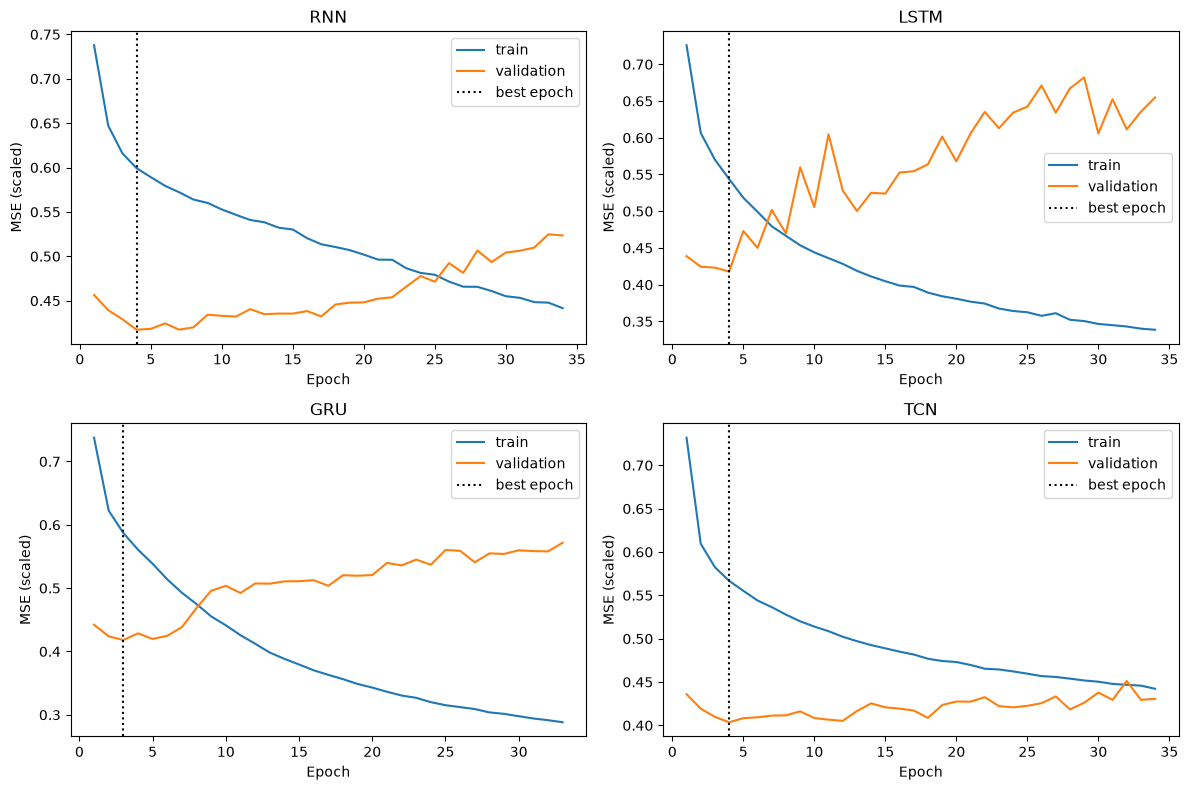

In [31]:
stage2_models, stage2_histories, stage2_costs = {}, {}, {}
for model_name, config in STAGE2_DEFAULTS.items():
    model, history, seconds = fit_stage2(model_name, config, (X_train, y_train), (X_val, y_val))
    stage2_models[model_name] = model
    stage2_histories[model_name] = history
    stage2_costs[model_name] = seconds
    register_model(model_name, model, seconds)
    print(f'{model_name}: {len(history["val"])} epochs, best epoch {np.argmin(history["val"]) + 1}, '
          f'{seconds:.1f} s | validation MAE {score("val").loc[model_name, "val MAE"]:.4f} kW', flush=True)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, hist) in zip(axes.flat, stage2_histories.items()):
    ax.plot(np.arange(1, len(hist['train']) + 1), hist['train'], label='train')
    ax.plot(np.arange(1, len(hist['val']) + 1), hist['val'], label='validation')
    ax.axvline(np.argmin(hist['val']) + 1, color='k', ls=':', label='best epoch')
    ax.set(title=name, xlabel='Epoch', ylabel='MSE (scaled)')
    ax.legend()
plt.tight_layout(); plt.show()

### Controlled validation comparison

Inference timing is median time per forecast from three repeated batches of up to 512 validation windows, after warm-up; it includes the relevant CPU/GPU prediction path and host transfer. GPU work is synchronized. Weight storage is the in-memory size of the learned parameter arrays, not peak memory, activations or full runtime memory. For baselines without learned weights, storage is zero.
When a previously saved Stage 1 tuned model is reloaded without its original timing, its training time is shown as unavailable rather than estimated.


In [32]:
stage2_model_objects = {name: predictors[name].args[0] for name in ('MLP', 'CNN', tuned)}
stage2_model_objects.update(stage2_models)

def stage2_inference_ms(name):
    X = X_val[:min(512, len(X_val))]
    fn = predictors[name]
    fn(X[:min(64, len(X))]); stage2_sync()
    measurements = []
    for _ in range(3):
        stage2_sync(); start = time.perf_counter()
        fn(X)
        stage2_sync(); measurements.append((time.perf_counter() - start) * 1000 / len(X))
    return float(np.median(measurements))

def stage2_weight_bytes(name):
    if name in stage2_model_objects:
        return sum(p.numel() * p.element_size() for p in stage2_model_objects[name].parameters())
    if name == 'Ridge':
        return ridge.coef_.nbytes + ridge.intercept_.nbytes
    return 0

def stage2_comparison():
    values = score('val')
    rows = []
    for name in predictors:
        h = stage2_histories.get(name, histories.get(name))
        rows.append({'model': name, 'validation MAE (kW)': values.loc[name, 'val MAE'],
                     'validation RMSE (kW)': values.loc[name, 'val RMSE'],
                     'parameters': info[name]['params'], 'train time (s)': info[name]['train time (s)'],
                     'inference ms / window (batch)': stage2_inference_ms(name),
                     'weights KiB (estimate)': stage2_weight_bytes(name) / 1024,
                     'epochs': len(h['val']) if h is not None else None,
                     'best validation epoch': int(np.argmin(h['val'])) + 1 if h is not None else None,
                     'seed': info[name]['seed']})
    return pd.DataFrame(rows).set_index('model').sort_values('validation MAE (kW)')

stage2_initial_comparison = stage2_comparison()
display(stage2_initial_comparison.round(4))

,validation MAE (kW),validation RMSE (kW),parameters,train time (s),inference ms / window (batch),weights KiB (estimate),epochs,best validation epoch,seed
model,,,,,,,,,
CNN (tuned),0.4381,0.6119,182680,NaN,0.0048,713.5938,NaN,NaN,42
Ridge,0.4427,0.6106,44376,0.2309,0.0028,173.3438,NaN,NaN,-
TCN,0.4431,0.6101,36408,43.9885,0.0152,142.2188,34.0,4.0,42
RNN,0.4483,0.6203,8856,12.6595,0.0017,34.5938,34.0,4.0,42
LSTM,0.4504,0.6208,21272,12.5596,0.0035,83.0938,34.0,4.0,42
CNN,0.4546,0.6142,88664,8.5813,0.0026,346.3438,31.0,1.0,42
GRU,0.4613,0.6210,24984,17.5597,0.0044,97.5938,33.0,3.0,42
MLP,0.4674,0.6239,545304,6.2745,0.0012,2130.0938,31.0,1.0,42
Seasonal naive (week),0.5216,0.7906,0,0.0000,0.0000,0.0000,NaN,NaN,-


### Validation-only grid search

The search space, budget and stopping rule were fixed above. We tune the best **untuned** neural family; the previously tuned Stage 1 model and the baselines remain in the final comparison but do not determine which neural-family grid is run.

In [ ]:
untuned_families = ['MLP', 'CNN', 'RNN', 'LSTM', 'GRU', 'TCN']
stage2_family = stage2_initial_comparison.loc[untuned_families, 'validation MAE (kW)'].idxmin()
stage2_grid = STAGE2_GRIDS[stage2_family]
print('Tuning:', stage2_family, '| trials: 32 | selection: validation MAE in kW')
stage2_trial_rows, stage2_best = [], None
for i, values in enumerate(itertools.product(*stage2_grid.values()), 1):
    config = dict(zip(stage2_grid, values))
    training = {k: config.pop(k) for k in ('lr', 'batch_size')}
    model, history, seconds = fit_stage2(stage2_family, config, (X_train, y_train), (X_val, y_val), **training)
    metric = evaluate(Y_kw['val'], to_kw(predict(model, X_val)))
    stage2_trial_rows.append({'trial': i, **config, **training, 'validation MAE (kW)': metric['MAE'],
                              'validation RMSE (kW)': metric['RMSE'], 'epochs': len(history['val']),
                              'best validation epoch': int(np.argmin(history['val'])) + 1,
                              'train time (s)': seconds})
    if stage2_best is None or metric['MAE'] < stage2_best['mae']:
        stage2_best = {'mae': metric['MAE'], 'model': model, 'config': config.copy(),
                       'training': training.copy(), 'history': history, 'seconds': seconds}
    print(f'Trial {i}/32 | validation MAE {metric["MAE"]:.4f} kW | {len(history["val"])} epochs | {seconds:.1f} s', flush=True)
stage2_trials = pd.DataFrame(stage2_trial_rows)
display(stage2_trials.sort_values('validation MAE (kW)').reset_index(drop=True))
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(stage2_trials['trial'], stage2_trials['validation MAE (kW)'])
ax.axhline(stage2_initial_comparison.loc[stage2_family, 'validation MAE (kW)'], color='k', ls='--', label='untuned')
ax.set(xlabel='Grid trial', ylabel='Validation MAE (kW)', title=f'Stage 2: {stage2_family} search')
ax.legend(); plt.tight_layout(); plt.show()

### Finalist and checkpoint

Compare the tuned candidate with all original and new candidates, including naive baselines and Ridge. The smallest validation MAE wins; exact ties use fewer parameters and then the model name. Test metrics do not participate in this decision. The checkpoint supports both neural and non-neural finalists.

In [ ]:
stage2_tuned_name = f'{stage2_family} (Stage 2 tuned)'
register_model(stage2_tuned_name, stage2_best['model'], stage2_best['seconds'])
stage2_models[stage2_tuned_name] = stage2_best['model']
stage2_model_objects[stage2_tuned_name] = stage2_best['model']
stage2_histories[stage2_tuned_name] = stage2_best['history']
stage2_final_comparison = stage2_comparison()
display(stage2_final_comparison.round(4))
ranked = stage2_final_comparison.reset_index().sort_values(['validation MAE (kW)', 'parameters', 'model'])
finalist_name = ranked.iloc[0]['model']
print('Validation-selected finalist:', finalist_name)
print('Validation MAE:', f"{ranked.iloc[0]['validation MAE (kW)']:.4f} kW")
print('Parameters:', int(ranked.iloc[0]['parameters']), '| batch inference ms/window:',
      f"{ranked.iloc[0]['inference ms / window (batch)']:.4f}")

checkpoint = {'name': finalist_name, 'lookback': LOOKBACK, 'horizon': HORIZON, 'target': TARGET,
              'features': FEATURES, 'x_mean': x_scaler.mean_.tolist(), 'x_scale': x_scaler.scale_.tolist(),
              'seed': SEED, 'validation_mae_kw': float(ranked.iloc[0]['validation MAE (kW)'])}
if finalist_name == 'Ridge':
    checkpoint.update(kind='ridge', coef=ridge.coef_.tolist(), intercept=np.asarray(ridge.intercept_).tolist(),
                      alpha=float(best_alpha))
elif finalist_name in ('Persistence', 'Seasonal naive (day)', 'Seasonal naive (week)'):
    checkpoint.update(kind='baseline', period={'Persistence': 1, 'Seasonal naive (day)': DAY,
                                               'Seasonal naive (week)': WEEK}[finalist_name])
else:
    if finalist_name == stage2_tuned_name:
        model_family, model_config = stage2_family, stage2_best['config']
    elif finalist_name == tuned:
        model_family, model_config = family, best['cfg']
    elif finalist_name in STAGE2_DEFAULTS:
        model_family, model_config = finalist_name, STAGE2_DEFAULTS[finalist_name]
    else:
        model_family, model_config = finalist_name, {}
    checkpoint.update(kind='neural', family=model_family, config=model_config,
                      state_dict={k: v.detach().cpu() for k, v in stage2_model_objects[finalist_name].state_dict().items()})
os.makedirs('models', exist_ok=True)
torch.save(checkpoint, 'models/stage2_finalist.pt')
print('Saved models/stage2_finalist.pt (model, configuration and preprocessing state)')

### Reload and verify the selected model

This lightweight check reconstructs the selected architecture or baseline and compares its output with the registered predictor on validation windows. It does not run another search or evaluate the test set.

In [ ]:
loaded = torch.load('models/stage2_finalist.pt', map_location='cpu', weights_only=True)
assert loaded['features'] == FEATURES and loaded['lookback'] == LOOKBACK and loaded['horizon'] == HORIZON
X_check = X_val[:32]
if loaded['kind'] == 'neural':
    restored = build_stage2(loaded['family'], **loaded['config']).to(device)
    restored.load_state_dict(loaded['state_dict'])
    restored_prediction = predict(restored, X_check)
elif loaded['kind'] == 'ridge':
    restored_prediction = flat(X_check) @ np.asarray(loaded['coef']).T + np.asarray(loaded['intercept'])
elif loaded['name'] == 'Persistence':
    restored_prediction = np.repeat(X_check[:, -1:, TARGET_IDX], HORIZON, axis=1)
else:
    period = loaded['period']
    restored_prediction = X_check[:, LOOKBACK - period:LOOKBACK - period + HORIZON, TARGET_IDX]
expected = predictors[finalist_name](X_check)
assert restored_prediction.shape == (len(X_check), HORIZON)
assert np.isfinite(restored_prediction).all() and np.allclose(restored_prediction, expected, rtol=1e-5, atol=1e-5)
print('Stage 2 checkpoint reload passed for', finalist_name, '| output:', restored_prediction.shape)

### Stage 2: forecast comparison on validation data

Compare all registered baselines and models, including the Stage 1 and Stage 2 tuned candidates. The left plot shows MAE at each hour ahead across all validation windows; the right plot shows their predictions for the middle validation window, selected by a fixed rule. This is a validation comparison, not a new test-set evaluation.

In [ ]:
# Fix the example in advance; forecasts are for the same 24 target hours for every model.
X_stage2_val, _, t_stage2_val = data['val']
example_index = len(X_stage2_val) // 2
example_hours = features.index[t_stage2_val[example_index]:t_stage2_val[example_index] + HORIZON]
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
colors = plt.get_cmap('tab20').colors

for i, name in enumerate(predictors):
    forecast = prediction(name, 'val')  # kW; cached after the first computation
    assert forecast.shape == Y_kw['val'].shape
    color = colors[i % len(colors)]
    step_mae = np.abs(forecast - Y_kw['val']).mean(axis=0)
    axes[0].plot(range(1, HORIZON + 1), step_mae, marker='.', lw=1.3, color=color, label=name)
    axes[1].plot(example_hours, forecast[example_index], lw=1.2, color=color, label=name)

axes[0].set(xlabel='Hours ahead', ylabel='Validation MAE (kW)',
            title='Stage 2 — error by forecast step')
axes[1].plot(example_hours, Y_kw['val'][example_index], color='black', lw=2.5, label='Actual', zorder=10)
axes[1].set(xlabel='Forecast hour', ylabel='Global active power (kW)',
            title=f'Stage 2 — 24-hour validation forecast starting {example_hours[0]}')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.20), ncol=2, fontsize=8)
axes[1].tick_params(axis='x', labelrotation=30)
plt.show()